# Exercise 1

- Implement your own version of the line-fitting procedure, using the same data.
- Now try it with the data in `lectures/data/linear_fits/data_1.txt`
    - First plot the data. What has changed?
    - Try the same model and likelihood on the new data. You might want to adjust the prior on $m$ and $b$ for this new data set.
    - What if you use the provided uncertainty per data point $\sigma_{y_i}$, instead of assuming a constant variance $\sigma_y$ for all data points?
    - Instead use the actual likelihood of the data:


\begin{aligned}
\mu(x_i) &= m x_i + b,\\
\sigma(x_i) &= \sigma_{y_i} + f\,\mu(x_i)^2, \qquad f > 0,\\
y_i &\sim \mathcal{N}\!\left(\mu(x_i),\,\sigma(x_i)^2\right).
\end{aligned}


Careful with the normalisation of the Gaussian likelihood. Because we vary the variance, this matters now!

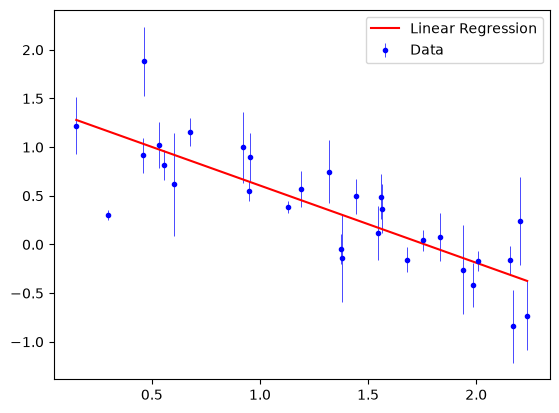

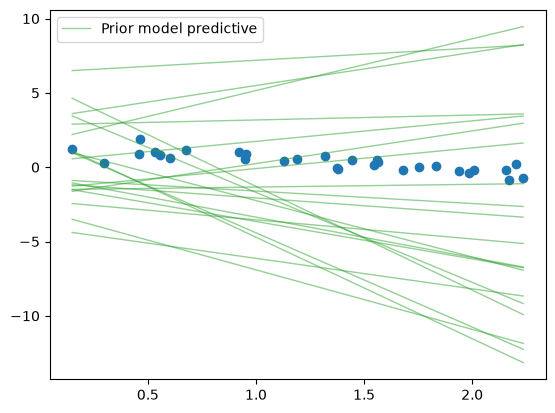

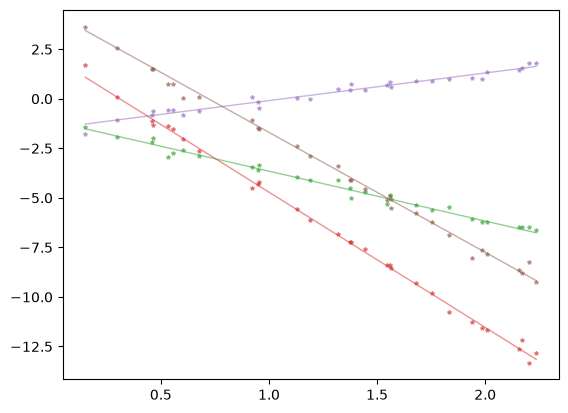

In [45]:
import numpy as np
import scipy.stats as ss
import matplotlib.pyplot as plt

x, y, y_err = np.loadtxt("../lectures/data/linear_fits/data_1.txt", unpack=True)

m_rg, b_rg = np.polyfit(x, y, deg=1)

#print(m_rg, b_rg)

plt.errorbar(x, y, yerr=y_err, fmt=".", color="blue", elinewidth=0.5, label="Data")
plt.plot(x, m_rg*x + b_rg, color="red", label="Linear Regression")
plt.legend()



def heterocedastic_model(m, b, x):
   return m*x + b

def sigma_y(m, b, x, y_err, f):
   sigma = y_err + f * heterocedastic_model(m, b, x)**2
   return sigma


def het_log_likelihood_probability(m, b, x, y, y_err, f):
   prediction = heterocedastic_model(m, b, x)

   n = len(y)

   sigma = sigma_y(m, b, x, y_err, f)

   return -0.5 * np.sum((y - prediction)**2/sigma**2) - 0.5*np.sum(np.log(2*np.pi*sigma**2))


# Define Priors for m and b

m_prior = ss.norm(loc=-0.5, scale=3)
b_prior = ss.norm(loc=1, scale=3)
f_prior = ss.norm(loc=0.5, scale= 1)






def het_log_prior(m, b, f):
   return m_prior.logpdf(m) + b_prior.logpdf(b) + f_prior.logpdf(f)


def prior_sampling(n_samples):
   return np.stack((m_prior.rvs(n_samples), b_prior.rvs(n_samples))).T

rng = np.random.default_rng(seed=42)

prior_model_predictive = np.array([heterocedastic_model(*parameters, x) for parameters in prior_sampling(n_samples=20)])


fig, ax = plt.subplots(1, 1)

ax.scatter(x,y)
style = dict(c="C2", lw=1, alpha=0.5)
ax.plot(x, prior_model_predictive.T, **style)
ax.plot([], [], label="Prior model predictive", **style)
ax.legend();

prior_predictive = (prior_model_predictive + y_err*rng.normal(size=prior_model_predictive.shape))


pmp_style = dict(lw=1, alpha=0.5)
pp_style = dict(ls="none", marker="*", ms=3, alpha=0.5)


fig, ax = plt.subplots(1, 1)

for i in range(4):
    ax.plot(x, prior_model_predictive[i], c=f"C{i+2}", **pmp_style)
    ax.plot(x, prior_predictive[i], c=f"C{i+2}", **pp_style)




In [39]:
import scipy.optimize as so

def log_posterior(m, b, f, x, y, y_err):
    return het_log_likelihood_probability(m, b, x, y, y_err, f) + het_log_prior(m, b, f)


def negative_log_post(theta, x, y, y_err):
    m, b, f = theta
    return -log_posterior(m, b, f, x, y, y_err)

MAP_result = so.minimize(fun=negative_log_post, x0=(-0.5, 1, 0.5), args=(x, y, y_err), method="L-BFGS-B")

m_MAP, b_MAP, f_MAP = MAP_result.x

print("MAP results")
print("m_MAP:", m_MAP)
print("b_MAP:", b_MAP)
print("f_MAP:", f_MAP)


MAP results
m_MAP: -0.7352727396293527
b_MAP: 1.2884641186062153
f_MAP: 0.2953481070827358


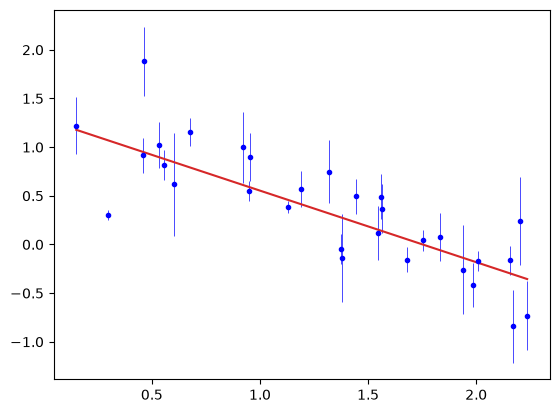

In [106]:
fig, ax = plt.subplots(1,1)


plt.errorbar(x, y, yerr=y_err, fmt=".", color="blue", elinewidth=0.5, label="Data")

ax.plot(x, heterocedastic_model(m_MAP, b_MAP, x), c="C3")


In [107]:
import emcee

# emcee passes an array of values for the sampled parameters
# This wrapper just splits the array theta into m and b
def log_posterior_wrapper(theta, x, y_err, y):
    m, b, f = theta
    return log_posterior(m, b, f, x, y, y_err)

# emcee requires some extra settings to run
n_param = 3       # Number of parameter we are sampling
n_walker = 10     # Number of walkers. This just needs to be 
                  # larger than 2*n_param + 1!
n_step = 5000     # How many steps each walker will take. The number
                  # of samples will be n_walker*n_step

# The starting point for each walker
theta_init = np.array([0.5, 0.5, 0.5]) \
    + 0.1*np.random.normal(size=(n_walker, n_param))

sampler = emcee.EnsembleSampler(
    nwalkers=n_walker, ndim=n_param,
    log_prob_fn=log_posterior_wrapper,
    args=(x, y_err, y)
)
state = sampler.run_mcmc(theta_init, nsteps=n_step)

In [108]:


# The samples will be correlated, this checks how correlated they are
# We will discuss this once we come to MCMC methods
print("Auto-correlation time:")
for name, value in zip(["m", "b", "f"], sampler.get_autocorr_time()):
    print(f"{name} = {value:.1f}")

# We need to discard the beginning of the chain (a few auto-correlation times)
# to get rid of the initial conditions
chain = sampler.get_chain(discard=300, thin=10, flat=True)



Auto-correlation time:
m = 56.8
b = 50.7
f = 48.9


In [109]:
print("Posterior results (mean±std)")
print(f"m = {np.mean(chain[:,0]):.2f}±{np.std(chain[:,0]):.2f}")
print(f"b = {np.mean(chain[:,1]):.2f}±{np.std(chain[:,1]):.2f}")
print(f"f = {np.mean(chain[:,2]):.2f}±{np.std(chain[:,2]):.2f}")

#print(chain[0,:])


Posterior results (mean±std)
m = -0.73±0.10
b = 1.27±0.17
f = 0.40±0.19


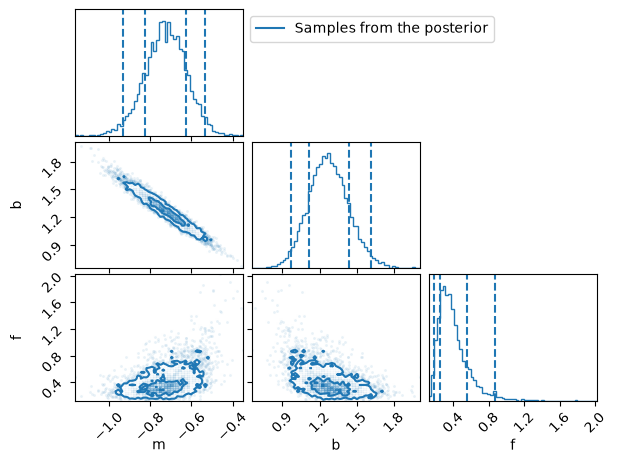

In [110]:
import corner

fig = plt.figure()
fig = corner.corner(
    chain,
    bins=60,
    labels=["m", "b", "f"],
    color="C0",
    levels=1-np.exp(-0.5*np.array([1, 2])**2), # Credible contours corresponding
    quantiles=[0.025, 0.16, 0.84, 0.975],
    fig=fig
);
fig.get_axes()[0].plot([], [], c="C0", label="Samples from the posterior")
fig.get_axes()[0].legend(loc=2, bbox_to_anchor=(1, 1))




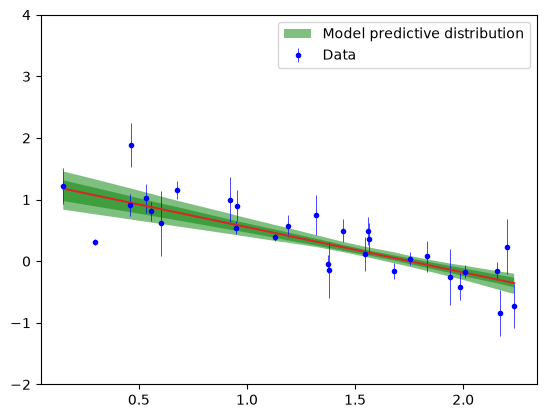

In [111]:
posterior_samples = chain[rng.choice(chain.shape[0], size=200)]

posterior_model_predictive = np.array([heterocedastic_model(samples[0], samples[1], x) for samples in posterior_samples])

model_quantiles = np.quantile(
    posterior_model_predictive, q=[0.025, 0.16, 0.84, 0.975], axis=0
)

fig, ax = plt.subplots()

plt.errorbar(x, y, yerr=y_err, fmt=".", color="blue", elinewidth=0.5, label="Data")
ax.plot(x, heterocedastic_model(m_MAP, b_MAP, x), c="C3")
ax.fill_between(x, model_quantiles[0], model_quantiles[-1], alpha=0.5, facecolor="green",
                label="Model predictive distribution")
ax.fill_between(x, model_quantiles[1], model_quantiles[-2], alpha=0.5, facecolor="green")
ax.set_ylim(-2, 4)
ax.legend()





# Exercise 2

The data in the previous example were a synthetic version of real observations that were obtained in an AstroWoche project in 2024 by Jonas Spiller, Theo Lequy, Clara Bleich. 

<!-- ![jovian moons data](../assets/jovian_moons_raw_data.png) -->
<img style="display: block; 
    margin-left: auto;
    margin-right: auto;
    width: 60%;"
    src="../assets/jovian_moons_raw_data.png" alt="jovian moons data"/>

The real observations can be found in `data/jovian_moons/{moon}.dat`:

In [ ]:
moon = "Io"

t, distance, distance_alt, distance_err = np.loadtxt(
    f"./data/jovian_moons/{moon}.dat", unpack=True)

1. Repeat the analysis with the real data set. What do you find?

There is another distance estimate provided. The difference between the distance estimates comes from different approaches to converting the measured distance between Jupiter and its moons from the number of pixels to a physical distance in km.

2. How does the analysis look when using this other distance estimate (what I call `distance_alt`)? What about the other moons?



Because there are two distance estimates that do not agree, both of which are based on reasonable approaches, this suggests that there might be a _systematic_ error in the measurements. Systematic errors are usually not random (which means they do not get smaller as you obtain more data). But we could pretend the offset between the two measurements is an estimate of an unaccounted statistical uncertainty. 

3. How does the analysis look when we assume `sigma_d**2 = distance_err**2 + (distance - distance_alt)**2`?



4. Instead of assuming that the uncertainty is underestimated by this offset, we can also model it. Does the model work better if the variance is a free parameter?
